In [16]:
import pandas as pd

# Load the CSV file
df = pd.read_csv("mallows_euclidean_gain_with_rank_diff.csv")

# Select and print the first 10 values of the desired columns
print(df[["phi_m", "phi_w", "rank_differences"]].tail(10))


      phi_m  phi_w                rank_differences
3590    1.0    1.0  [2, 0, 8, 9, 4, 0, 1, 0, 0, 0]
3591    1.0    1.0  [0, 0, 3, 0, 0, 2, 0, 0, 7, 4]
3592    1.0    1.0  [0, 9, 0, 2, 1, 0, 0, 0, 2, 0]
3593    1.0    1.0  [0, 4, 0, 0, 0, 0, 6, 0, 2, 0]
3594    1.0    1.0  [1, 0, 8, 0, 5, 0, 7, 0, 1, 0]
3595    1.0    1.0  [3, 1, 0, 3, 4, 2, 4, 1, 3, 0]
3596    1.0    1.0  [4, 7, 0, 0, 4, 0, 7, 0, 0, 0]
3597    1.0    1.0  [2, 0, 0, 0, 0, 0, 0, 0, 3, 0]
3598    1.0    1.0  [2, 0, 0, 2, 0, 6, 3, 1, 2, 0]
3599    1.0    1.0  [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


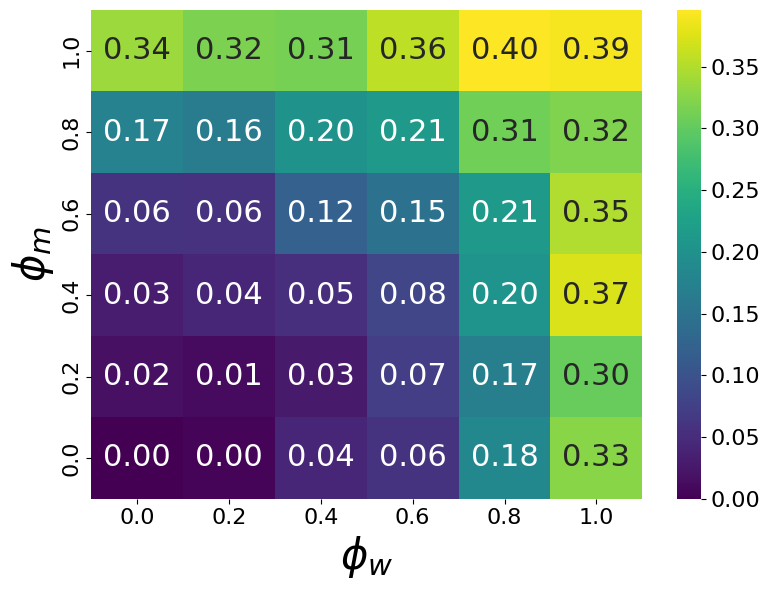

In [4]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_euclidean_gain_with_rank_diff.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["trunc_count"].mean().reset_index()

heatmap_data["trunc_count"] = heatmap_data["trunc_count"] / 10

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="trunc_count")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)

plt.tight_layout()

plt.savefig("trunc_count_mall_euc.pdf", format="pdf")
plt.show()


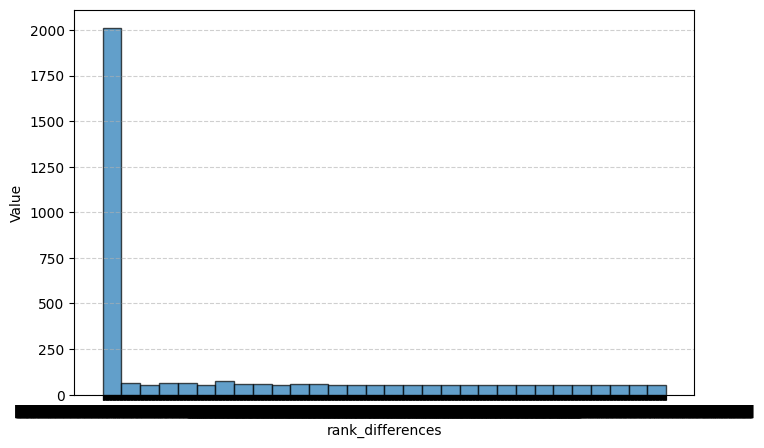

TypeError: Could not convert string '[0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0, 0, 0, 0, 0, 0, 0, 0, 0, 0][0,

In [1]:
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_euclidean_gain_with_rank_diff.csv")
 
# Quick sanity check

#print(df.head())
 
# Plot distribution of avg_self_benefit

plt.figure(figsize=(8, 5))

plt.hist(df["rank_differences"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of avg_self_benefit")

plt.xlabel("rank_differences")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()
 
# Compute mean and median

mean_val = df["rank_differences"].mean()

median_val = df["rank_differences"].median()

max_val = df["rank_differences"].max()
 
print(f"rank differences mean: {mean_val:.4f}")

print(f"rank differences median: {median_val:.4f}")

print(f"rank differences max: {max_val:.4f}")

 
import pandas as pd

import matplotlib.pyplot as plt
 
# Load the CSV

df = pd.read_csv("mallows_euclidean_gain_with_rank_diff.csv")
 
# Filter only positive avg_self_benefit values

positive_df = df[df["rank_differences"] > 0]
 
# Plot distribution for positive values

plt.figure(figsize=(8, 5))

plt.hist(positive_df["rank_differences"], bins=30, edgecolor="black", alpha=0.7)

#plt.title("Distribution of Positive avg_self_benefit")

plt.xlabel("rank_differences")

plt.ylabel("Value")

plt.grid(axis="y", linestyle="--", alpha=0.6)
 
# Compute mean, median, max for positive values

mean_pos = positive_df["rank_differences"].mean()

median_pos = positive_df["rank_differences"].median()

max_pos = positive_df["rank_differences"].max()
 
# Add vertical lines for mean, median, max

plt.axvline(mean_pos, color="red", linestyle="--", linewidth=2, label=f"Mean = {mean_pos:.2f}")

plt.axvline(median_pos, color="blue", linestyle=":", linewidth=2, label=f"Median = {median_pos:.2f}")

plt.axvline(max_pos, color="green", linestyle="-.", linewidth=2, label=f"Max = {max_pos:.2f}")
 
plt.legend()

plt.show()
 
print(f"Mean of rank differences: {mean_pos:.4f}")

print(f"Median of rank differences: {median_pos:.4f}")

print(f"Max of rank differences: {max_pos:.4f}")

 

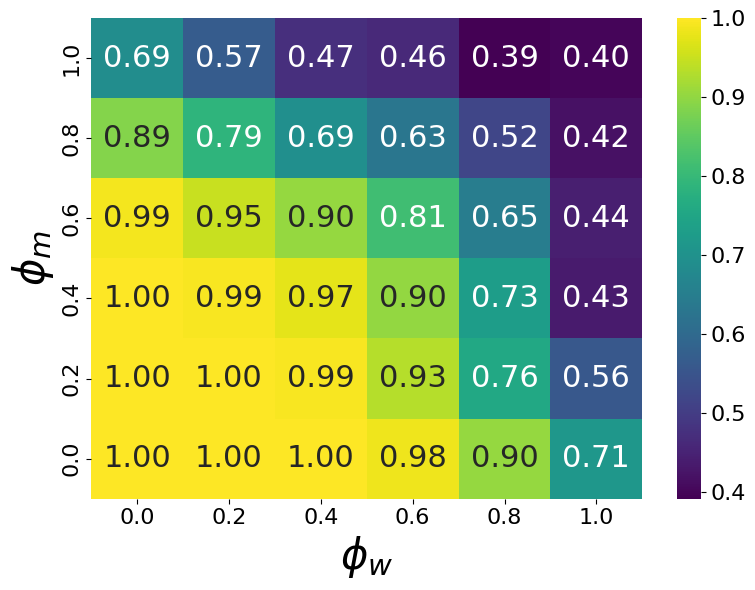

In [26]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_MD_gain_with_rank_diff.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["trunc_count"].mean().reset_index()

heatmap_data["trunc_count"] = heatmap_data["trunc_count"] / 10

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="trunc_count")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("trunc_count_mall_MD.pdf", format="pdf")
plt.show()


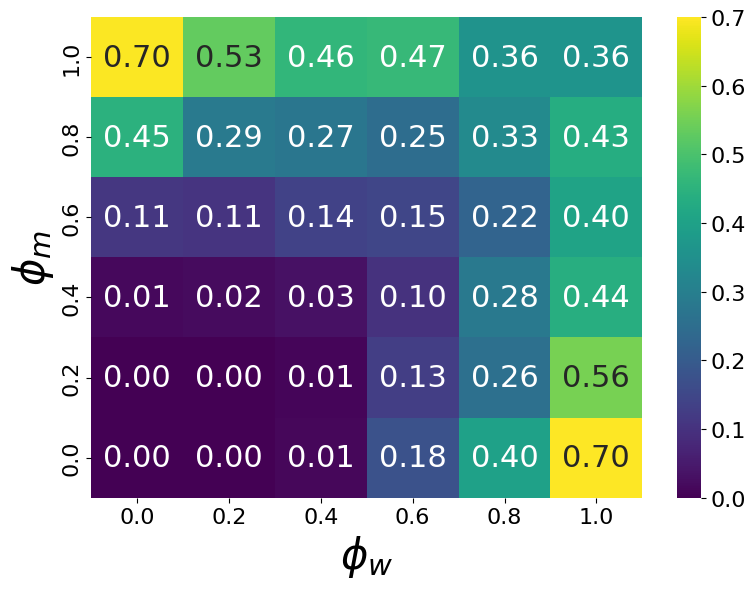

In [23]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_MA_gain_with_rank_diff.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
#df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["trunc_count"].mean().reset_index()

heatmap_data["trunc_count"] = heatmap_data["trunc_count"] / 10

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="trunc_count")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)


plt.tight_layout()
plt.savefig("trunc_count_mall_MA.pdf", format="pdf")
plt.show()


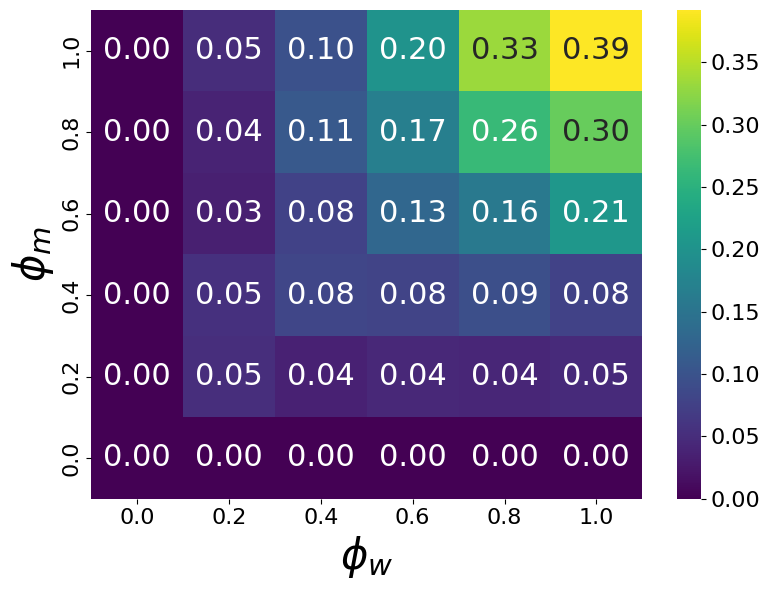

In [1]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_gain_with_rank_diff.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["trunc_count"].mean().reset_index()

heatmap_data["trunc_count"] = heatmap_data["trunc_count"] / 10

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="trunc_count")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)

plt.tight_layout()
#plt.savefig("trunc_count_mallows.pdf", format="pdf")
plt.show()


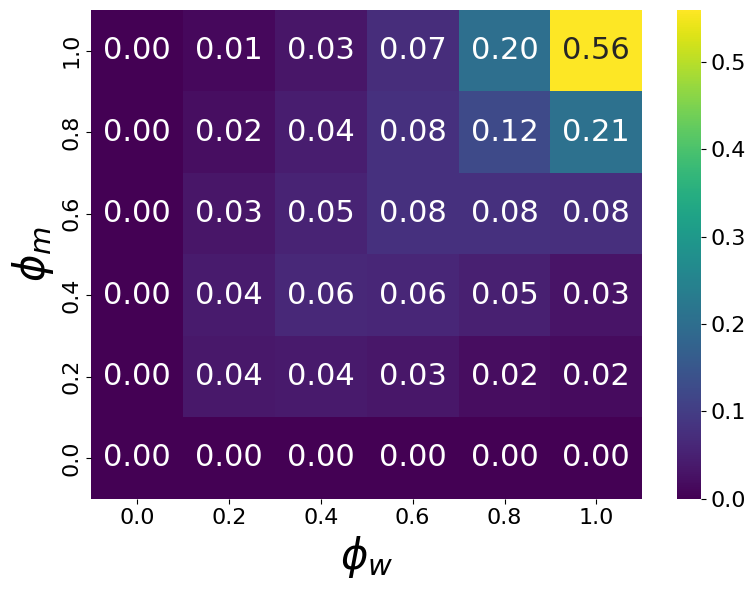

In [5]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("mallows_accomplice_with_rank_diff.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["phi_m", "phi_w"])["trunc_count"].mean().reset_index()

heatmap_data["trunc_count"] = heatmap_data["trunc_count"] / 30

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="phi_m", columns="phi_w", values="trunc_count")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel(r"$\phi_w$", fontsize = 30)
plt.ylabel(r"$\phi_m$", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)

plt.tight_layout()
plt.savefig("trunc_count_mallows_30.pdf", format="pdf")
plt.show()


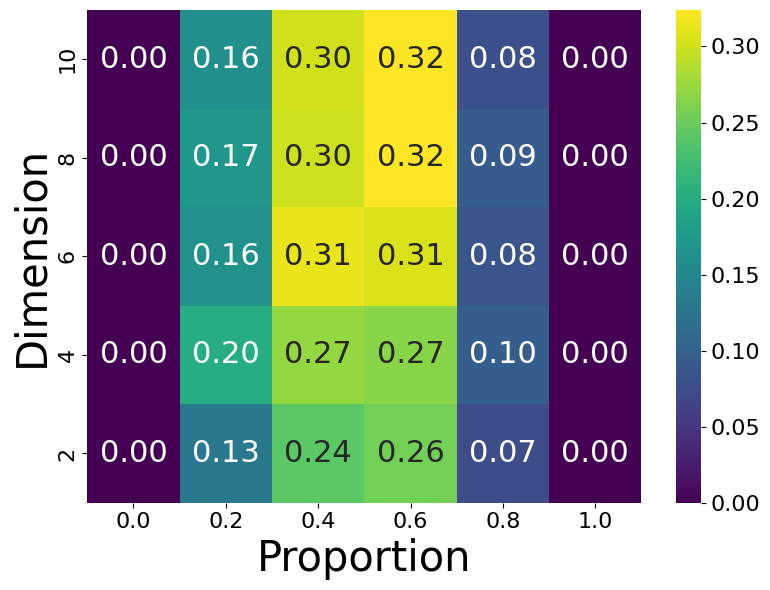

In [2]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("reverse_euclidean_gain_with_rank_diff.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["dimension", "proportion"])["trunc_count"].mean().reset_index()

heatmap_data["trunc_count"] = heatmap_data["trunc_count"] / 10

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="dimension", columns="proportion", values="trunc_count")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel("Proportion", fontsize = 30)
plt.ylabel("Dimension", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)

plt.tight_layout()
plt.savefig("trunc_count_rev_euc.pdf", format="pdf")
plt.show()


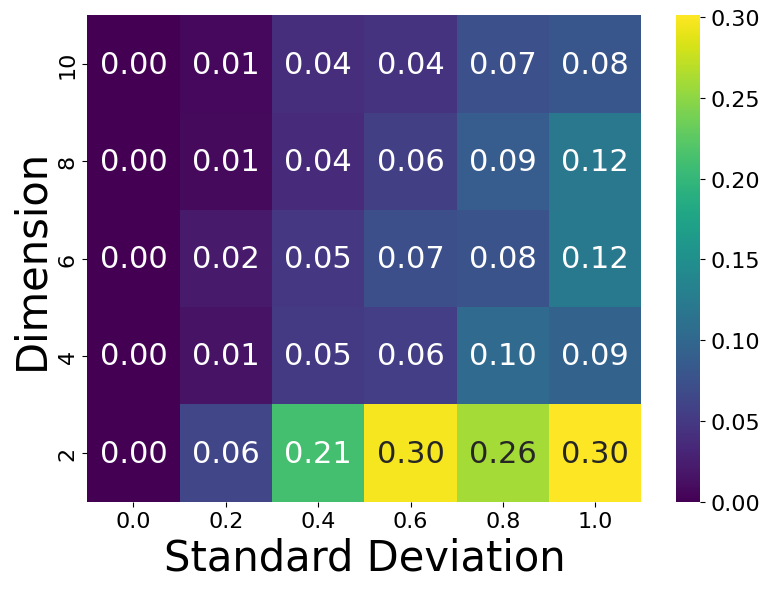

In [3]:
import pandas as pd
import ast
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV
df = pd.read_csv("expectations_euclidean_gain_with_rank_diff.csv")

# Safely convert string to list (if needed)
def count_positive(lst_str):
    try:
        lst = ast.literal_eval(lst_str)  # convert string -> list
        return sum(1 for x in lst if x > 0)
    except (ValueError, SyntaxError):
        return 0  # fallback if parsing fails

# Create trunc_count column
df["trunc_count"] = df["rank_differences"].apply(count_positive)

# Compute average trunc_count grouped by phi_m and phi_w
heatmap_data = df.groupby(["dimension", "std"])["trunc_count"].mean().reset_index()

heatmap_data["trunc_count"] = heatmap_data["trunc_count"] / 10

# Pivot for heatmap
pivot_table = heatmap_data.pivot(index="dimension", columns="std", values="trunc_count")

# Plot heatmap
plt.figure(figsize=(8, 6))
ax = sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="viridis", annot_kws={"size": 22}
)
#plt.title("Mallows MA")
plt.xlabel("Standard Deviation", fontsize = 30)
plt.ylabel("Dimension", fontsize=30)
plt.gca().invert_yaxis()

plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=16)

plt.tight_layout()
plt.savefig("trunc_count_exp_euc.pdf", format="pdf")
plt.show()
